In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:37340")
client

<Client: 'tcp://127.0.0.1:37340' processes=8 threads=32, memory=503.70 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
for pp in range(6,9):
    if pp == 6:
        ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(level=slice(1,None)
                                  ).chunk({"time":4,"level":1,"y":128,"x":256})
    else:
        tmp = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(time=slice(1,None),
                                   level=slice(1,None)
                                  ).chunk({"time":4,"level":1,"y":128,"x":256}
                                         )
        time = tmp.time.data + ds.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time", time)
        ds = xr.concat([ds, tmp], "time")
        tmp.close()
    
ds

<xarray.Dataset> Size: 254GB
Dimensions:  (time: 630, level: 4, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 16B 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    h        (time, level, y, x) float32 85GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    u.x      (time, level, y, x) float32 85GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    u.y      (time, level, y, x) float32 85GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>

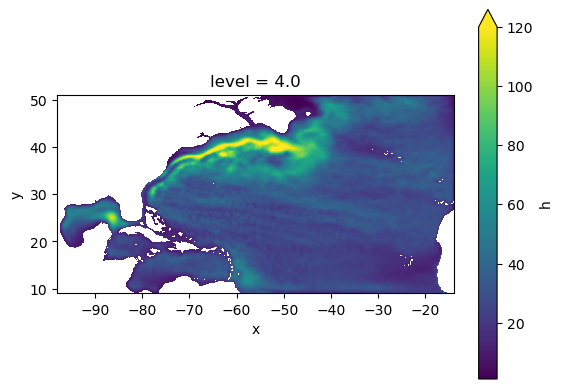

In [9]:
fig, ax = plt.subplots()
ds.h.where(ds.h>0.).isel(level=-1).std("time").plot(ax=ax, vmax=1.2e2, 
                                                    rasterized=True)
ax.set_aspect("equal")

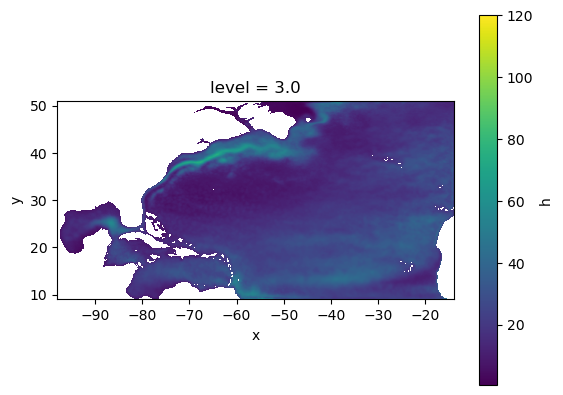

In [10]:
fig, ax = plt.subplots()
ds.h.where(ds.h>0.).isel(level=-2).std("time").plot(ax=ax, vmax=1.2e2, 
                                                    rasterized=True)
ax.set_aspect("equal")

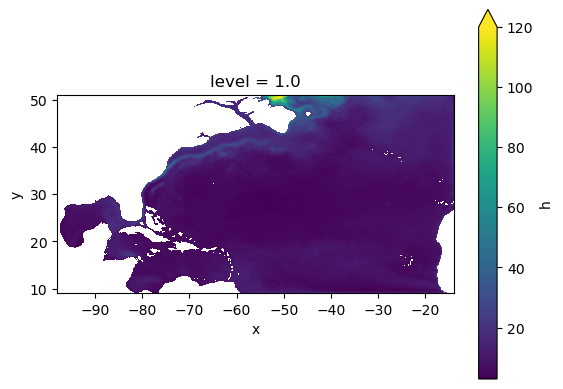

In [5]:
fig, ax = plt.subplots()
ds.h.where(ds.h>0.).isel(level=0).std("time").plot(ax=ax, vmax=1.2e2, 
                                                    rasterized=True)
ax.set_aspect("equal")

Fitted Equation: y = 0.0105 * e^(0.2000 * x) + -0.0311


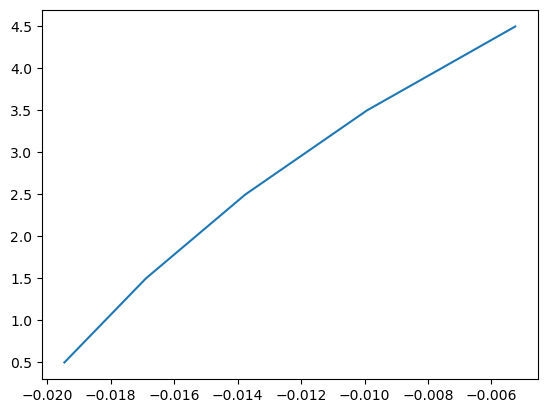

<xgcm.Grid>
X Axis (not periodic, boundary='fill'):
  * center   x --> inner
  * inner    xG --> center
Y Axis (not periodic, boundary='fill'):
  * center   y --> inner
  * inner    yG --> center
Z Axis (not periodic, boundary='fill'):
  * center   level --> outer
  * outer    lu --> center


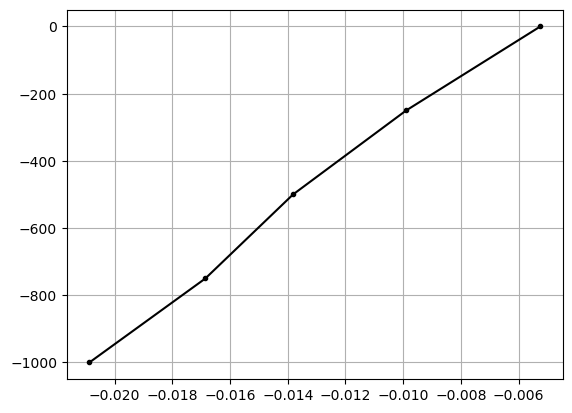

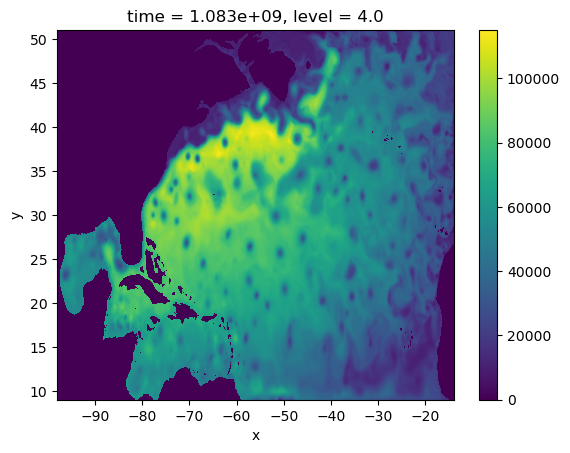

(<xarray.DataArray (time: 419, level: 4, y: 2048, x: 4096)> Size: 112GB
 dask.array<transpose, shape=(419, 4, 2048, 4096), dtype=float64, chunksize=(4, 1, 128, 4096), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 2kB 0.0 2.592e+06 5.184e+06 ... 1.081e+09 1.083e+09
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01,
 <xarray.DataArray (time: 419, level: 4, y: 2048, x: 4096)> Size: 112GB
 dask.array<transpose, shape=(419, 4, 2048, 4096), dtype=float64, chunksize=(4, 1, 2048, 256), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 2kB 0.0 2.592e+06 5.184e+06 ... 1.081e+09 1.083e+09
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01)

In [24]:
llo, lla = np.meshgrid(ds.x, ds.y)
xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
                  coords={"y":ds.y.data,
                          "xG":.5*(ds.x.data[1:]+ds.x.data[:-1])}
                 )
yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
                  coords={"yG":.5*(ds.y.data[1:]+ds.y.data[:-1]),
                          "x":ds.x.data}
                 )
cori = gsw.f(ds.y)

ds.coords["yG"] = ("yG",.5*(ds.y.data[1:]+ds.y.data[:-1]))
ds.coords["xG"] = ("xG",.5*(ds.x.data[1:]+ds.x.data[:-1]))
# ds2.coords["ll"] = ("ll",np.arange(-.5,5,1.))
grid = Grid(ds, periodic=None, autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level"}
                   })
print(grid)

fig, ax = plt.subplots()
ax.plot(ds.b, -np.array([1000,750,500,250,0]), "k.-")
ax.grid(True)
plt.show()

v_x = grid.interp(grid.diff(ds["u.y"].fillna(0.).chunk({"x":-1}), "X", boundary="extend"
                           ) / xxG, 
                  "X", boundary="extend")
u_y = grid.interp(grid.diff(ds["u.x"].fillna(0.).chunk({"y":-1}), "Y", boundary="extend"
                           ) / yyG, 
                  "Y", boundary="extend")
# v_x = (ds["u.y"].fillna(0.).diff("x").dropna("x")
#        / xxG.data
#       ).chunk({"y":128,"x":256})
# u_y = (ds["u.x"].fillna(0.).diff("y").dropna("y")
#        / yyG.data
#       ).chunk({"y":128,"x":256})
# v_x = v_x.reset_index("x", drop=False)
# v_x = v_x.reset_coords("x", drop=True)
# v_x.coords["x"] = ("x",xxG.xG.data)
# u_y = u_y.reset_index("y", drop=False)
# u_y = u_y.reset_coords("y", drop=True)
# u_y.coords["y"] = ("y",yyG.yG.data)
# v_x = (xxG**-1 * ds["u.y"].isel(level=-1).diff("x").dropna("x").data
#       ).interp(xG=ds.x.data)
# u_y = (yyG**-1 * ds["u.x"].isel(level=-1).diff("y").dropna("x").data
#       ).interp(yG=ds.y.data)

v_x, u_y

In [ ]:
hbar = ds.h.mean(["time"]).compute()
maskh = xr.DataArray(np.ma.masked_values(hbar,0.).mask,
                     dims=hbar.dims, 
                     coords=hbar.coords
                    )

dsave = hbar.to_dataset(name="hbar")
dsave["ubar"] = (ds["u.x"].mean("time")).where(~maskh, 0.)
dsave["vbar"] = (ds["u.y"].mean("time")).where(~maskh, 0.)
dsave["uhat"] = ((ds.h * ds["u.x"]).mean("time")
                 / hbar).where(~maskh, 0.)
dsave["vhat"] = ((ds.h * ds["u.y"]).mean("time")
                 / hbar).where(~maskh, 0.)
print(dsave)
dsave.chunk({"level":1,"y":256,"x":512}
           ).to_zarr(op.join(ddir,"SW/48/mean/UVh.zarr"), mode="w")
dsave.close()

In [7]:
dsb = xr.open_zarr(op.join(ddir,"SW/48/mean/UVh.zarr")
                  ).chunk({"level":1,"y":128,"x":256}
                         )
maskh = xr.DataArray(np.ma.masked_values(dsb.hbar,0.).mask,
                     dims=dsb.hbar.dims, coords=dsb.hbar.coords
                    )

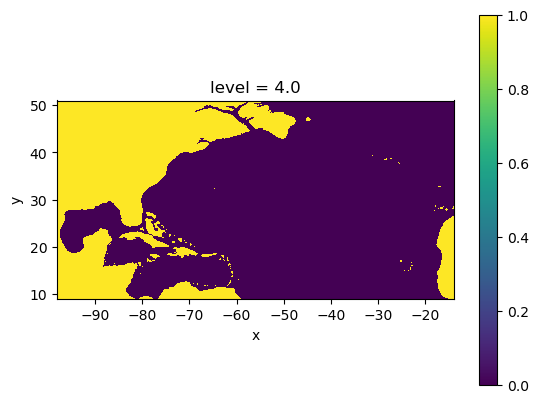

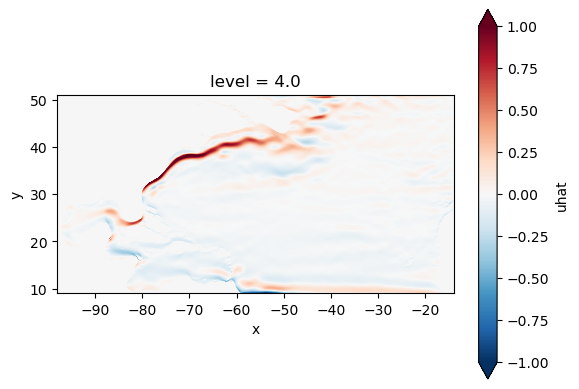

In [6]:
fig, ax = plt.subplots()
maskh.isel(level=-1).plot(ax=ax, rasterized=True)
ax.set_aspect("equal")
plt.show()

fig, ax = plt.subplots()
dsb.uhat.isel(level=-1).plot(ax=ax, vmax=1., rasterized=True)
ax.set_aspect("equal")

In [9]:
upp = ds["u.x"] - dsb.uhat
vpp = ds["u.y"] - dsb.vhat

dsave = upp.to_dataset(name="upp")
dsave["vpp"] = vpp
print(dsave)
dsave.chunk({"time":10,"level":1,"y":256,"x":512}
           ).to_zarr(op.join(ddir,"SW/48/TWA/Upp.zarr"), mode="w")

<xarray.Dataset> Size: 169GB
Dimensions:  (time: 630, level: 4, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 16B 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    upp      (time, level, y, x) float32 85GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    vpp      (time, level, y, x) float32 85GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 41.19 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [10]:
up = ds["u.x"] - dsb.ubar
vp = ds["u.y"] - dsb.vbar
dsave = up.to_dataset(name="up")
dsave["vp"] = vp
print(dsave)
dsave.chunk({"time":10,"level":1,"y":256,"x":512}
           ).to_zarr(op.join(ddir,"SW/48/TWA/Up.zarr"), mode="w")

<xarray.Dataset> Size: 169GB
Dimensions:  (time: 630, level: 4, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 16B 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    up       (time, level, y, x) float32 85GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    vp       (time, level, y, x) float32 85GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 41.19 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 169GB
Dimensions:  (time: 630, level: 4, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 16B 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    up       (time, level, y, x) float32 85GB dask.array<chunksize=(10, 1, 256, 512), meta=np.ndarray>
    vp       (time, level, y, x) float32 85GB dask.array<chunksize=(10, 1, 256, 512), meta=np.ndarray> <xarray.Dataset> Size: 169GB
Dimensions:  (time: 630, level: 4, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 16B 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    

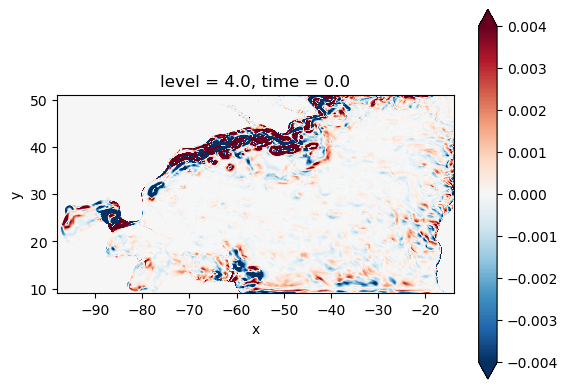

In [5]:
dsp  = xr.open_zarr(op.join(ddir,"SW/48/TWA/Up.zarr"))
dspp = xr.open_zarr(op.join(ddir,"SW/48/TWA/Upp.zarr"))
print(dsp, dspp)
Ep = .5*(dsp.up**2 + dsp.vp**2)
Epp = .5*(dspp.upp**2 + dspp.vpp**2)

fig, ax = plt.subplots()
(Epp - Ep).isel(time=0,level=-1).plot(ax=ax, vmax=.004, rasterized=True)
ax.set_aspect("equal")

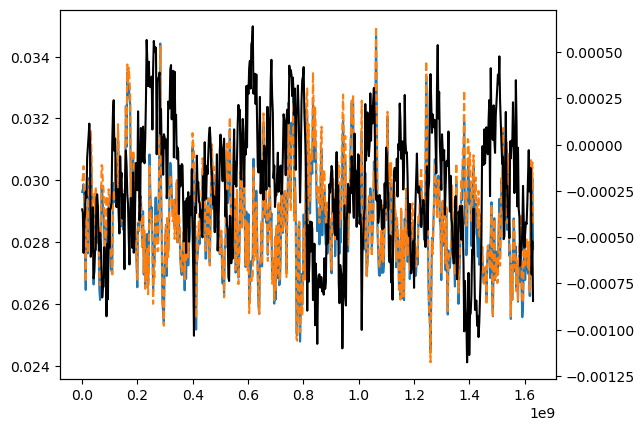

In [8]:
fig, ax = plt.subplots()
ax2 = ax.twinx()
ax.plot(Ep.time, 
        Ep.isel(level=-1).where(~maskh.isel(level=-1)).mean(["y","x"],skipna=True))
ax.plot(Epp.time, 
        Epp.isel(level=-1).where(~maskh.isel(level=-1)).mean(["y","x"],skipna=True), ls="--")
ax2.plot(Epp.time, 
         (Ep - Epp).isel(level=-1).where(~maskh.isel(level=-1)).mean(["y","x"],skipna=True), "k")

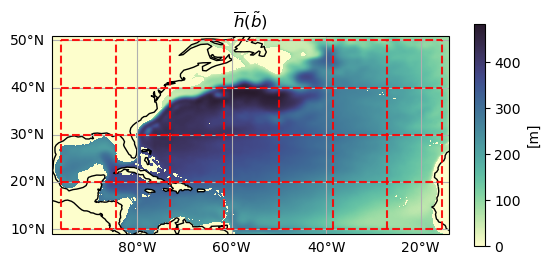

In [6]:
yy = np.arange(10,60,10)
xx = np.arange(-96.,-15,11.5)

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([dsb.x.min(), dsb.x.max(), dsb.y.min(), dsb.y.max()], 
              crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m')
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(dsb.x, dsb.y, dsb.hbar.isel(level=-1), 
                  cmap=cmocean.cm.deep,
                  rasterized=True)

for yyy in yy:
    ax.plot(xx, np.ones_like(xx)*yyy, "r--", alpha=.9)
for xxx in xx:
    ax.plot(np.ones_like(yy)*xxx, yy, "r--", alpha=.9)
ax.set_aspect("equal")

# ax.set_xlabel(r"Longitude")
# ax.set_ylabel(r"Latitude")
ax.set_title(r"$\overline{h}(\tilde{b})$", fontsize=12)
cb = fig.colorbar(im, ax=ax, shrink=.6)
cb.set_label(r"[m]")
plt.savefig(op.join(ddir,"Figs/hbar.pdf"))

In [7]:
ds.h.sum("level").where(ds.h.sum("level")>0.).min(skipna=True).values

array(1333.3446, dtype=float32)

In [50]:
dspp.time.diff("time")/86400.

<xarray.DataArray 'time' (time: 418)> Size: 2kB
array([30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30., 30.,
       30., 30.], dtype=float32)
Coordinates:
  * time     (time) float32 2kB 2.592e+06 5.184e+06 ... 1.081e+09 1.083e+09

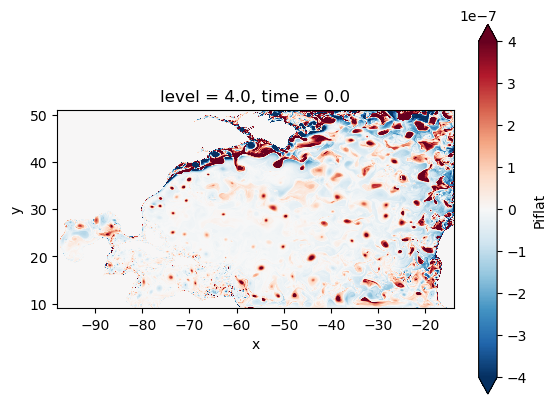

In [12]:
dpv = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/surf.zarr"))
fig, ax = plt.subplots()
dpv.Piflat.isel(time=0).plot(ax=ax, vmax=4e-7, rasterized=True)
ax.set_aspect("equal")

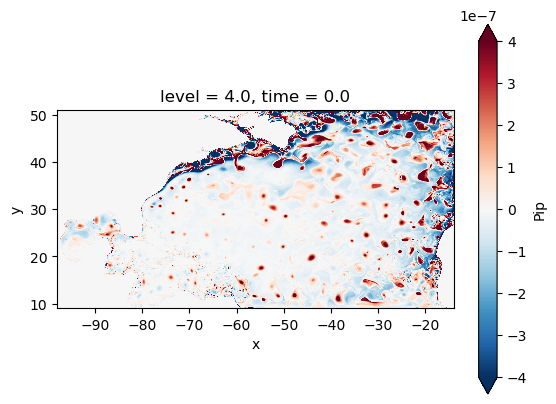

In [13]:
fig, ax = plt.subplots()
dpv.Pip.isel(time=0).plot(ax=ax, vmax=4e-7, rasterized=True)
ax.set_aspect("equal")

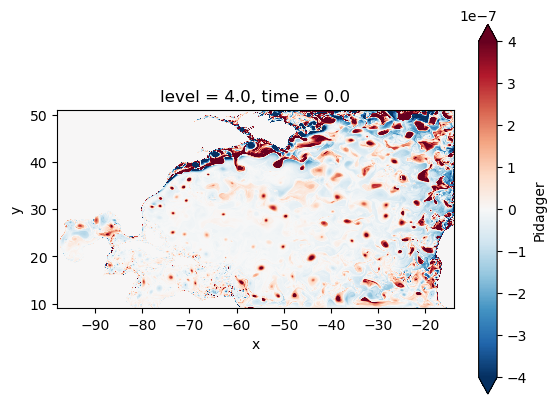

In [18]:
fig, ax = plt.subplots()
dpv.Pidagger.isel(time=0).plot(ax=ax, vmax=4e-7, rasterized=True)
ax.set_aspect("equal")

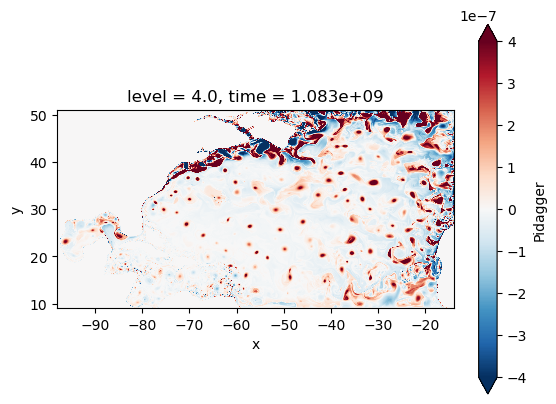

In [26]:
fig, ax = plt.subplots()
dpv.Pidagger.isel(time=-1).plot(ax=ax, vmax=4e-7, rasterized=True)
ax.set_aspect("equal")

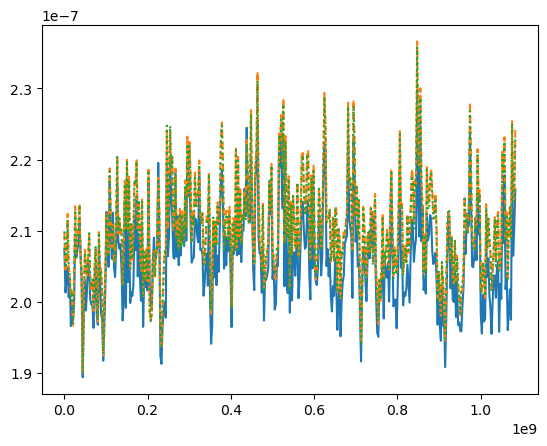

In [21]:
fig, ax = plt.subplots()
ax.plot(dpv.time, dpv.Pip.where(~maskh.isel(level=-1)).std(["y","x"]))
ax.plot(dpv.time, dpv.Piflat.where(~maskh.isel(level=-1)).std(["y","x"]), ls="--")
ax.plot(dpv.time, dpv.Pidagger.where(~maskh.isel(level=-1)).std(["y","x"]), ls=":")

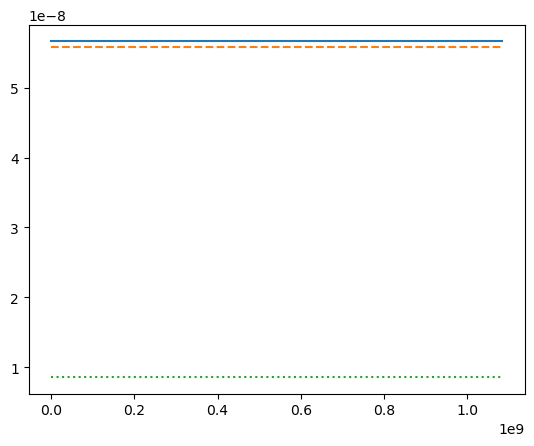

In [24]:
dfp = (dpv.Piflat - dpv.Pip)
ddp = (dpv.Pidagger - dpv.Pip)
dfd = (dpv.Piflat - dpv.Pidagger)

fig, ax = plt.subplots()
ax.plot(dfp.time, dfp.where(~maskh.isel(level=-1)).std(["y","x"]))
ax.plot(ddp.time, ddp.where(~maskh.isel(level=-1)).std(["y","x"]), ls="--")
ax.plot(dfd.time, dfd.where(~maskh.isel(level=-1)).std(["y","x"]), ls=":")

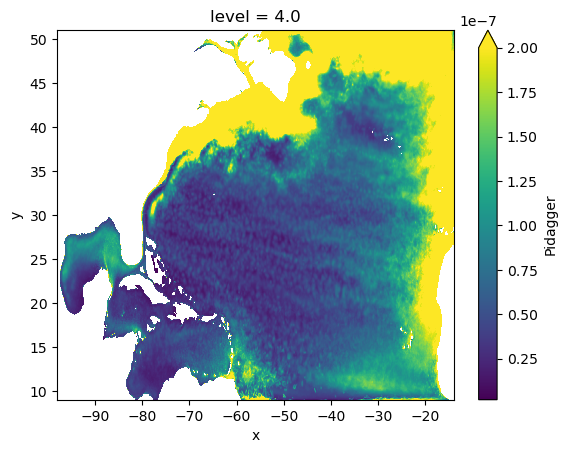

In [13]:
dpv.Pidagger.std("time").where(~maskh.isel(level=-1)).plot(vmax=4e-7)

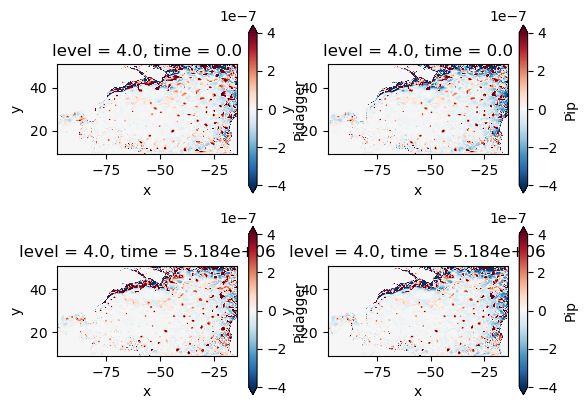

In [9]:
fig, axes = plt.subplots(nrows=2, ncols=2)
dpv.Pidagger.isel(time=0).plot(ax=axes[0,0], vmax=4e-7, rasterized=True)
dpv.Pip.isel(time=0).plot(ax=axes[1,0], vmax=4e-7, rasterized=True)
dpv.Pidagger.isel(time=2).plot(ax=axes[0,1], vmax=4e-7, rasterized=True)
dpv.Pip.isel(time=2).plot(ax=axes[1,1], vmax=4e-7, rasterized=True)
axes[0,0].set_aspect("equal")
axes[0,1].set_aspect("equal")
axes[1,0].set_aspect("equal")
axes[1,1].set_aspect("equal")

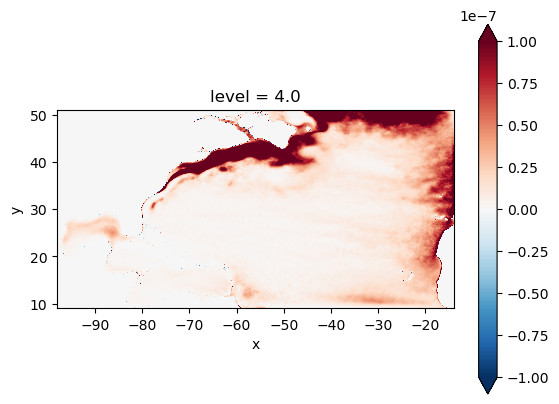

In [23]:
fig, ax = plt.subplots()
(ddp).mean("time").plot(ax=ax, vmax=1e-7, rasterized=True)
ax.set_aspect("equal")

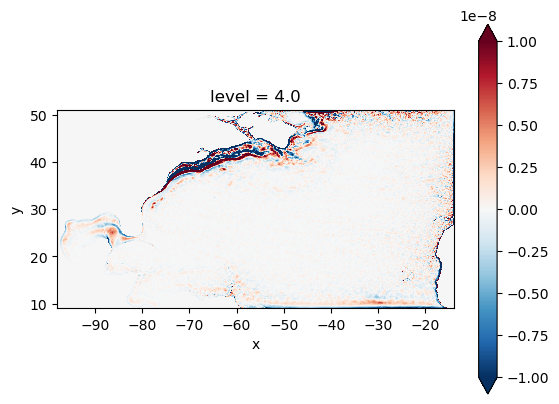

In [24]:
fig, ax = plt.subplots()
(dfd).mean("time").plot(ax=ax, vmax=1e-8, rasterized=True)
ax.set_aspect("equal")

In [30]:
v_x, u_y

(<xarray.DataArray 'u.y' (time: 419, y: 2048, x: 4095)> Size: 28GB
 dask.array<truediv, shape=(419, 2048, 4095), dtype=float64, chunksize=(10, 256, 511), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 2kB 0.0 2.592e+06 5.184e+06 ... 1.081e+09 1.083e+09
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.97 -97.95 -97.93 ... -14.05 -14.03 -14.01
     level    float32 4B 4.0,
 <xarray.DataArray 'u.x' (time: 419, y: 2047, x: 4096)> Size: 28GB
 dask.array<truediv, shape=(419, 2047, 4096), dtype=float64, chunksize=(10, 255, 512), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 2kB 0.0 2.592e+06 5.184e+06 ... 1.081e+09 1.083e+09
   * y        (y) float32 8kB 9.031 9.051 9.072 9.092 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
     level    float32 4B 4.0)